“This is the import and setup section of my Colab code. I imported the libraries required for my EEG emotion-classification project. Pandas is used for handling the dataset, NumPy for numerical operations, Matplotlib for graphs, Scikit-learn for splitting, normalization, label encoding and evaluation metrics, and TensorFlow/Keras for building and training the CNN and Attention deep-learning model. I also imported the different neural-network layers that I needed for my model. At this stage, I am only preparing the environment; the dataset is not trained in this particular code.”

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    Dense,
    Dropout,
    Flatten,
    LSTM,
    Attention,
    Add,
    GlobalAveragePooling1D,
    LayerNormalization
)

from tensorflow.keras.utils import to_categorical

# Reproducibility
tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)
print("Setup completed successfully.")

TensorFlow version: 2.21.0
Setup completed successfully.


“This code is used in Google Colab to upload my dataset from my computer into the Colab environment.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving emotions synthetic 5class.csv to emotions synthetic 5class.csv


“Here I loaded my collected EEG emotion dataset into Pandas using read_csv(). Then I used df.shape to check the number of rows and columns in the dataset, and df.head() to display the first five rows and verify that the dataset was loaded correctly.”

In [ ]:
import pandas as pd

df = pd.read_csv("emotions synthetic 5class.csv")


In [ ]:
print("Dataset shape:", df.shape)

print("\nClass distribution:")
print(df["label"].value_counts())

print("\nClass percentages:")
print(df["label"].value_counts(normalize=True) * 100)

print("\nFeature statistics:")
display(df.describe())

Dataset shape: (2500, 29)

Class distribution:
label
SAD      500
FEAR     500
ANGRY    500
HAPPY    500
CALM     500
Name: count, dtype: int64

Class percentages:
label
SAD      20.0
FEAR     20.0
ANGRY    20.0
HAPPY    20.0
CALM     20.0
Name: proportion, dtype: float64

Feature statistics:


,TP9_delta,TP9_theta,TP9_alpha,TP9_beta,TP9_gamma,TP9_mean,TP9_std,AF7_delta,AF7_theta,AF7_alpha,...,AF8_gamma,AF8_mean,AF8_std,TP10_delta,TP10_theta,TP10_alpha,TP10_beta,TP10_gamma,TP10_mean,TP10_std
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,...,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,3.147918,2.794101,2.966935,3.412580,1.979908,-0.001757,1.001595,3.141494,2.808172,2.949529,...,1.968636,-0.002051,0.984936,3.143099,2.819750,2.965760,3.436854,1.963620,-0.015915,0.994567
std,0.596784,1.055380,1.776073,1.927143,1.324676,1.009875,0.302778,0.610213,1.058888,1.768224,...,1.304273,0.973955,0.301262,0.596626,1.054614,1.776122,1.931488,1.299734,0.980097,0.303167
min,1.076400,0.352800,0.010000,0.010000,0.010000,-3.585000,0.025000,1.258800,0.499400,0.010000,...,0.010000,-3.451400,0.050700,1.194100,0.475400,0.341800,0.311100,0.010000,-3.160900,0.021800
25%,2.748600,2.057675,1.675225,1.471800,0.770375,-0.688625,0.799725,2.726650,2.072000,1.639650,...,0.769000,-0.648425,0.787000,2.735075,2.059300,1.658050,1.440350,0.777125,-0.682650,0.787700
50%,3.128300,2.517800,2.273250,3.647200,1.869650,-0.021150,0.999050,3.111450,2.533150,2.239250,...,1.851050,-0.013150,0.983200,3.116850,2.552750,2.288350,3.755950,1.883150,-0.028100,0.997650
75%,3.549650,3.285225,3.871650,4.931675,2.952450,0.676000,1.209025,3.543700,3.307450,3.916800,...,2.927975,0.659725,1.188475,3.535625,3.314150,3.909050,4.984500,2.946850,0.642650,1.199900
max,5.516500,6.500700,8.329000,8.725500,6.887100,3.682500,1.991600,5.562700,7.238100,8.103300,...,6.309800,3.388900,1.995700,6.161200,6.944700,8.347100,8.635800,6.921500,3.423300,2.167300


In [ ]:
# Check whether participant/session information exists

print("All columns:")
for i, col in enumerate(df.columns):
    print(i, ":", col)

All columns:
0 : TP9_delta
1 : TP9_theta
2 : TP9_alpha
3 : TP9_beta
4 : TP9_gamma
5 : TP9_mean
6 : TP9_std
7 : AF7_delta
8 : AF7_theta
9 : AF7_alpha
10 : AF7_beta
11 : AF7_gamma
12 : AF7_mean
13 : AF7_std
14 : AF8_delta
15 : AF8_theta
16 : AF8_alpha
17 : AF8_beta
18 : AF8_gamma
19 : AF8_mean
20 : AF8_std
21 : TP10_delta
22 : TP10_theta
23 : TP10_alpha
24 : TP10_beta
25 : TP10_gamma
26 : TP10_mean
27 : TP10_std
28 : label


In [ ]:
print("Columns in dataset:")
print(df.columns.tolist())

print("\nPossible participant-related columns:")

for col in df.columns:
    if any(word in col.lower() for word in [
        "participant", "subject", "person", "user", "session"
    ]):
        print(col)


Columns in dataset:
['TP9_delta', 'TP9_theta', 'TP9_alpha', 'TP9_beta', 'TP9_gamma', 'TP9_mean', 'TP9_std', 'AF7_delta', 'AF7_theta', 'AF7_alpha', 'AF7_beta', 'AF7_gamma', 'AF7_mean', 'AF7_std', 'AF8_delta', 'AF8_theta', 'AF8_alpha', 'AF8_beta', 'AF8_gamma', 'AF8_mean', 'AF8_std', 'TP10_delta', 'TP10_theta', 'TP10_alpha', 'TP10_beta', 'TP10_gamma', 'TP10_mean', 'TP10_std', 'label']

Possible participant-related columns:


In [ ]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (2500, 29)

Column names:
['TP9_delta', 'TP9_theta', 'TP9_alpha', 'TP9_beta', 'TP9_gamma', 'TP9_mean', 'TP9_std', 'AF7_delta', 'AF7_theta', 'AF7_alpha', 'AF7_beta', 'AF7_gamma', 'AF7_mean', 'AF7_std', 'AF8_delta', 'AF8_theta', 'AF8_alpha', 'AF8_beta', 'AF8_gamma', 'AF8_mean', 'AF8_std', 'TP10_delta', 'TP10_theta', 'TP10_alpha', 'TP10_beta', 'TP10_gamma', 'TP10_mean', 'TP10_std', 'label']

First 5 rows:


,TP9_delta,TP9_theta,TP9_alpha,TP9_beta,TP9_gamma,TP9_mean,TP9_std,AF7_delta,AF7_theta,AF7_alpha,...,AF8_mean,AF8_std,TP10_delta,TP10_theta,TP10_alpha,TP10_beta,TP10_gamma,TP10_mean,TP10_std,label
0,3.4834,4.6080,2.7124,0.9515,0.7892,-0.2152,0.1792,3.8646,4.7115,1.5710,...,1.3553,0.5503,3.9593,5.0834,2.3647,0.7693,0.5057,-0.6115,1.6114,SAD
1,3.2141,4.7441,1.4586,1.0900,0.3954,1.4059,1.1400,3.2002,3.8519,2.3133,...,-0.2665,0.8104,3.9534,4.1740,1.1491,1.0205,0.4308,-0.0260,1.0803,SAD
2,3.6796,4.0359,1.7851,0.6694,0.4866,-0.4691,1.1979,3.3582,5.0196,1.3705,...,0.0850,0.7205,3.3027,5.2745,2.3542,0.7790,0.5182,-0.1916,0.9345,SAD
3,3.5102,2.3178,0.2333,6.0016,0.9816,-0.4911,1.5377,3.5259,3.3361,1.8704,...,0.0642,1.0700,3.3999,2.4038,0.7044,5.6956,2.9206,-1.8935,0.8122,FEAR
4,3.4655,2.4732,1.6357,4.1016,2.2728,-0.6427,0.6730,3.2093,1.9865,1.5427,...,-0.4995,0.9491,2.4003,1.8292,1.7580,5.2957,2.7919,0.8167,1.3600,ANGRY



Data types:
TP9_delta     float64
TP9_theta     float64
TP9_alpha     float64
TP9_beta      float64
TP9_gamma     float64
TP9_mean      float64
TP9_std       float64
AF7_delta     float64
AF7_theta     float64
AF7_alpha     float64
AF7_beta      float64
AF7_gamma     float64
AF7_mean      float64
AF7_std       float64
AF8_delta     float64
AF8_theta     float64
AF8_alpha     float64
AF8_beta      float64
AF8_gamma     float64
AF8_mean      float64
AF8_std       float64
TP10_delta    float64
TP10_theta    float64
TP10_alpha    float64
TP10_beta     float64
TP10_gamma    float64
TP10_mean     float64
TP10_std      float64
label          object
dtype: object

Missing values:
TP9_delta     0
TP9_theta     0
TP9_alpha     0
TP9_beta      0
TP9_gamma     0
TP9_mean      0
TP9_std       0
AF7_delta     0
AF7_theta     0
AF7_alpha     0
AF7_beta      0
AF7_gamma     0
AF7_mean      0
AF7_std       0
AF8_delta     0
AF8_theta     0
AF8_alpha     0
AF8_beta      0
AF8_gamma     0
AF8_mean      

In [ ]:
print("Label column:", df.columns[-1])

print("\nEmotion classes:")
print(df.iloc[:, -1].value_counts())

print("\nNumber of classes:")
print(df.iloc[:, -1].nunique())

Label column: label

Emotion classes:
label
SAD      500
FEAR     500
ANGRY    500
HAPPY    500
CALM     500
Name: count, dtype: int64

Number of classes:
5


In [ ]:
# ===== DATASET VERIFICATION =====

print("========== DATASET VERIFICATION ==========")

print("Shape:", df.shape)

print("\nColumns:")
for col in df.columns:
    print("-", col)

label_col = df.columns[-1]

print("\nLabel column:", label_col)

print("\nClass distribution:")
print(df[label_col].value_counts())

print("\nNumber of classes:", df[label_col].nunique())

print("\nMissing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

========== DATASET VERIFICATION ==========
Shape: (2500, 29)

Columns:
- TP9_delta
- TP9_theta
- TP9_alpha
- TP9_beta
- TP9_gamma
- TP9_mean
- TP9_std
- AF7_delta
- AF7_theta
- AF7_alpha
- AF7_beta
- AF7_gamma
- AF7_mean
- AF7_std
- AF8_delta
- AF8_theta
- AF8_alpha
- AF8_beta
- AF8_gamma
- AF8_mean
- AF8_std
- TP10_delta
- TP10_theta
- TP10_alpha
- TP10_beta
- TP10_gamma
- TP10_mean
- TP10_std
- label

Label column: label

Class distribution:
label
SAD      500
FEAR     500
ANGRY    500
HAPPY    500
CALM     500
Name: count, dtype: int64

Number of classes: 5

Missing values: 0
Duplicate rows: 0

Data types:
TP9_delta     float64
TP9_theta     float64
TP9_alpha     float64
TP9_beta      float64
TP9_gamma     float64
TP9_mean      float64
TP9_std       float64
AF7_delta     float64
AF7_theta     float64
AF7_alpha     float64
AF7_beta      float64
AF7_gamma     float64
AF7_mean      float64
AF7_std       float64
AF8_delta     float64
AF8_theta     float64
AF8_alpha     float64
AF8_beta 

“Here I separated the input features from the output label. I removed the label column from the dataset and stored the remaining 28 EEG features in X. I stored the emotion labels separately in y. This is called separating the features and target before training the model

In [ ]:
# Separate features and target label

X = df.drop("label", axis=1)
y = df["label"]

# Expected EEG feature order
EXPECTED_FEATURES = [
    "TP9_delta", "TP9_theta", "TP9_alpha", "TP9_beta", "TP9_gamma", "TP9_mean", "TP9_std",
    "AF7_delta", "AF7_theta", "AF7_alpha", "AF7_beta", "AF7_gamma", "AF7_mean", "AF7_std",
    "AF8_delta", "AF8_theta", "AF8_alpha", "AF8_beta", "AF8_gamma", "AF8_mean", "AF8_std",
    "TP10_delta", "TP10_theta", "TP10_alpha", "TP10_beta", "TP10_gamma", "TP10_mean", "TP10_std"
]

# Check that all 28 features exist in the correct order
assert X.columns.tolist() == EXPECTED_FEATURES, (
    "Feature columns or order do not match the expected EEG feature structure."
)

print("Features shape:", X.shape)
print("Labels shape:", y.shape)
print("Feature order verified successfully.")

Features shape: (2500, 28)
Labels shape: (2500,)
Feature order verified successfully.


Here I converted the emotion labels from text into numerical values because the deep-learning model needs numerical labels for training. I used LabelEncoder to assign a unique number to each emotion.”

In [ ]:

# Separate features and target labels
X = df.drop("label", axis=1)
y = df["label"]

# Convert emotion labels into numbers
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Emotion classes:")
print(label_encoder.classes_)

print("\nEncoded labels:")
print(y_encoded[:20])


Emotion classes:
['ANGRY' 'CALM' 'FEAR' 'HAPPY' 'SAD']

Encoded labels:
[4 4 4 2 0 3 0 2 1 2 1 1 3 4 3 3 4 0 1 4]


“Here I divided the encoded dataset into three parts: training, validation, and testing. I used 70% of the data for training and the remaining 30% was split equally into validation and testing, giving 15% each. I used stratification so that all five emotion classes remained properly represented in each set.”

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

Training data: (1750, 28)
Validation data: (375, 28)
Testing data: (375, 28)


“Here I standardized the EEG features using StandardScaler. I first fitted the scaler only on the training data and then used the same scaler to transform the validation and testing data. This brings the features to a comparable scale and helps the neural network train more effectively.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit only on training data
X_train = scaler.fit_transform(X_train)

# Transform validation and test using the same scaler
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Scaled training data:", X_train.shape)
print("Scaled validation data:", X_val.shape)
print("Scaled testing data:", X_test.shape)

Scaled training data: (1750, 28)
Scaled validation data: (375, 28)
Scaled testing data: (375, 28)


“Here I reshaped the 28 EEG features into a 4 × 7 format so that the data could be given as input to the Conv1D CNN. Since I have 4 EEG channels and 7 features for each channel, each sample is represented as 4 rows and 7 features.”

“Here I converted the numerical emotion labels into one-hot encoded format because my neural network has five output classes. Each emotion is represented as a vector of length 5, with 1 for the correct emotion and 0 for the other emotions.”

“Here I implemented the CNN baseline model for my EEG emotion-classification project. I defined the CNN architecture, compiled it with the Adam optimizer and categorical cross-entropy loss, and then displayed the model summary. This CNN is used as the baseline model before comparing it with my proposed CNN + Attention model.”

In [ ]:
import tensorflow as tf
from tensorflow.keras import backend as K

K.clear_session()

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)

cnn_model = Sequential([
    Input(shape=(4, 7)),

    Conv1D(
        filters=64,
        kernel_size=2,
        activation="relu",
        padding="same"
    ),

    MaxPooling1D(pool_size=2),

    Conv1D(
        filters=128,
        kernel_size=2,
        activation="relu",
        padding="same"
    ),

    GlobalAveragePooling1D(),

    Dense(64, activation="relu"),

    Dropout(0.3),

    Dense(5, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 4, 64)          │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 2, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 2, 128)         │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,053 (101.77 KB)

 Trainable params: 26,053 (101.77 KB)

 Non-trainable params: 0 (0.00 B)

“Here I trained my CNN model using the training dataset. I gave the model the training EEG features and their corresponding emotion labels. I used the validation dataset during training to monitor how well the model generalizes to unseen data. I trained it for 30 epochs with a batch size of 32.”

In [ ]:
X_train = X_train.reshape(-1, 4, 7)
X_val = X_val.reshape(-1, 4, 7)
X_test = X_test.reshape(-1, 4, 7)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

Training shape: (1750, 4, 7)
Validation shape: (375, 4, 7)
Testing shape: (375, 4, 7)


In [ ]:
from tensorflow.keras.utils import to_categorical

num_classes = 5

y_train_cat = to_categorical(y_train, num_classes)
y_val_cat = to_categorical(y_val, num_classes)
y_test_cat = to_categorical(y_test, num_classes)

print("Training labels:", y_train_cat.shape)
print("Validation labels:", y_val_cat.shape)
print("Testing labels:", y_test_cat.shape)

Training labels: (1750, 5)
Validation labels: (375, 5)
Testing labels: (375, 5)


In [ ]:
# Find the original CSV row corresponding to X_test[0]

import numpy as np
import pandas as pd

df = pd.read_csv("emotions synthetic 5class.csv")

feature_cols = [
    "TP9_delta", "TP9_theta", "TP9_alpha", "TP9_beta", "TP9_gamma", "TP9_mean", "TP9_std",
    "AF7_delta", "AF7_theta", "AF7_alpha", "AF7_beta", "AF7_gamma", "AF7_mean", "AF7_std",
    "AF8_delta", "AF8_theta", "AF8_alpha", "AF8_beta", "AF8_gamma", "AF8_mean", "AF8_std",
    "TP10_delta", "TP10_theta", "TP10_alpha", "TP10_beta", "TP10_gamma", "TP10_mean", "TP10_std"
]

# Recreate the same preprocessing
X_raw = df[feature_cols].values
y_raw = df["label"].values

# Find rows matching the scaled X_test[0]
# First inverse-transform the sample
sample_original = scaler.inverse_transform(
    X_test[0].reshape(1, -1)
).reshape(-1)

# Compare with original feature rows
differences = np.max(
    np.abs(X_raw - sample_original),
    axis=1
)

matched_index = np.argmin(differences)

print("Matching CSV row (0-based):", matched_index)
print("Matching CSV row (1-based):", matched_index + 1)
print("Maximum difference:", differences[matched_index])
print("Original label:", df.iloc[matched_index]["label"])

Matching CSV row (0-based): 1669
Matching CSV row (1-based): 1670
Maximum difference: 1.1102230246251565e-16
Original label: CALM


In [ ]:
import numpy as np

sample = X_test[1:2]

prediction = model.predict(sample, verbose=0)

predicted_class = np.argmax(prediction, axis=1)[0]
confidence = np.max(prediction, axis=1)[0]

predicted_label = label_encoder.inverse_transform([predicted_class])[0]

# Find which original CSV row this sample came from
sample_original = scaler.inverse_transform(
    X_test[1].reshape(1, -1)
).reshape(-1)

differences = np.max(
    np.abs(X_raw - sample_original),
    axis=1
)

matched_index = np.argmin(differences)

print("CSV row (1-based):", matched_index + 1)
print("Original label:", df.iloc[matched_index]["label"])
print("Notebook emotion:", predicted_label)
print("Notebook confidence:", f"{confidence*100:.2f}%")

NameError: name 'model' is not defined

In [ ]:
import tensorflow as tf
from tensorflow.keras import backend as K

K.clear_session()

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)

cnn_model = Sequential([
    Input(shape=(4, 7)),

    Conv1D(
        filters=64,
        kernel_size=2,
        activation="relu",
        padding="same"
    ),

    MaxPooling1D(pool_size=2),

    Conv1D(
        filters=128,
        kernel_size=2,
        activation="relu",
        padding="same"
    ),

    GlobalAveragePooling1D(),

    Dense(64, activation="relu"),

    Dropout(0.3),

    Dense(5, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 4, 64)          │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 2, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 2, 128)         │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,053 (101.77 KB)

 Trainable params: 26,053 (101.77 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history_cnn = cnn_model.fit(
    X_train,
    y_train_cat,
    validation_data=(X_val, y_val_cat),
    epochs=30,
    batch_size=32,
    verbose=1
)

Epoch 1/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.7577 - loss: 0.7561 - val_accuracy: 0.9520 - val_loss: 0.2230
Epoch 2/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9314 - loss: 0.1980 - val_accuracy: 0.9573 - val_loss: 0.1210
Epoch 3/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9463 - loss: 0.1439 - val_accuracy: 0.9600 - val_loss: 0.1082
Epoch 4/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9623 - loss: 0.1105 - val_accuracy: 0.9573 - val_loss: 0.1125
Epoch 5/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9606 - loss: 0.1087 - val_accuracy: 0.9573 - val_loss: 0.1022
Epoch 6/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9686 - loss: 0.0810 - val_accuracy: 0.9573 - val_loss: 0.1078
Epoch 7/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9686 - loss: 0.0869 - val_accuracy: 0.9627 - val_loss: 0.1021
Epoch 8/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9680 - loss: 0.0772 - val_accuracy: 0.9573 - val_loss

In [ ]:
cnn_predictions = cnn_model.predict(X_test)

cnn_pred_labels = np.argmax(cnn_predictions, axis=1)
cnn_true_labels = np.argmax(y_test_cat, axis=1)

print("Test samples:", len(cnn_true_labels))
print("Correct predictions:", (cnn_true_labels == cnn_pred_labels).sum())
print("Incorrect predictions:", (cnn_true_labels != cnn_pred_labels).sum())

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
Test samples: 375
Correct predictions: 361
Incorrect predictions: 14


In [ ]:
# Evaluate CNN on the unseen test dataset

cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    X_test,
    y_test_cat,
    batch_size=32,
    verbose=1
)

print("CNN Test Loss:", cnn_test_loss)
print("CNN Test Accuracy:", cnn_test_accuracy)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9627 - loss: 0.0978 
CNN Test Loss: 0.09780700504779816
CNN Test Accuracy: 0.9626666903495789


“Here I calculated the performance metrics of my trained CNN model on the test dataset. First, the model predicts the probability of each of the five emotions for the test samples. I then convert the highest probability into the predicted emotion class and compare those predictions with the actual test labels. Finally, I calculate accuracy, weighted precision, weighted recall and weighted F1-score.”


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

accuracy_cnn = accuracy_score(cnn_true_labels, cnn_pred_labels)

precision_cnn = precision_score(
    cnn_true_labels, cnn_pred_labels, average="macro"
)

recall_cnn = recall_score(
    cnn_true_labels, cnn_pred_labels, average="macro"
)

f1_macro_cnn = f1_score(
    cnn_true_labels, cnn_pred_labels, average="macro"
)

f1_weighted_cnn = f1_score(
    cnn_true_labels, cnn_pred_labels, average="weighted"
)

balanced_accuracy_cnn = balanced_accuracy_score(
    cnn_true_labels, cnn_pred_labels
)

print("========== CNN BASELINE RESULTS ==========")
print("Accuracy:", accuracy_cnn)
print("Macro Precision:", precision_cnn)
print("Macro Recall:", recall_cnn)
print("Macro F1:", f1_macro_cnn)
print("Weighted F1:", f1_weighted_cnn)
print("Balanced Accuracy:", balanced_accuracy_cnn)

print("\nClassification Report:")
print(
    classification_report(
        cnn_true_labels,
        cnn_pred_labels,
        target_names=label_encoder.classes_
    )
)

print("\nExact Confusion Matrix:")
print(confusion_matrix(cnn_true_labels, cnn_pred_labels))

========== CNN BASELINE RESULTS ==========
Accuracy: 0.9626666666666667
Macro Precision: 0.9627824230563956
Macro Recall: 0.9626666666666667
Macro F1: 0.9626600284495022
Weighted F1: 0.9626600284495023
Balanced Accuracy: 0.9626666666666667

Classification Report:
              precision    recall  f1-score   support

       ANGRY       0.90      0.92      0.91        75
        CALM       1.00      1.00      1.00        75
        FEAR       0.92      0.89      0.91        75
       HAPPY       1.00      1.00      1.00        75
         SAD       1.00      1.00      1.00        75

    accuracy                           0.96       375
   macro avg       0.96      0.96      0.96       375
weighted avg       0.96      0.96      0.96       375


Exact Confusion Matrix:
[[69  0  6  0  0]
 [ 0 75  0  0  0]
 [ 8  0 67  0  0]
 [ 0  0  0 75  0]
 [ 0  0  0  0 75]]


In [ ]:
print(confusion_matrix(cnn_true_labels, cnn_pred_labels))

[[69  0  6  0  0]
 [ 0 75  0  0  0]
 [ 8  0 67  0  0]
 [ 0  0  0 75  0]
 [ 0  0  0  0 75]]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict probabilities on the test data
cnn_predictions = cnn_model.predict(
    X_test,
    verbose=0
)

# Convert probabilities to class numbers
cnn_pred_labels = np.argmax(
    cnn_predictions,
    axis=1
)

# Calculate metrics
cnn_accuracy = accuracy_score(
    y_test,
    cnn_pred_labels
)

cnn_precision = precision_score(
    y_test,
    cnn_pred_labels,
    average="weighted"
)

cnn_recall = recall_score(
    y_test,
    cnn_pred_labels,
    average="weighted"
)

cnn_f1 = f1_score(
    y_test,
    cnn_pred_labels,
    average="weighted"
)

print("CNN Accuracy :", cnn_accuracy)
print("CNN Precision:", cnn_precision)
print("CNN Recall   :", cnn_recall)
print("CNN F1-score :", cnn_f1)

CNN Accuracy : 0.9626666666666667
CNN Precision: 0.9627824230563956
CNN Recall   : 0.9626666666666667
CNN F1-score : 0.9626600284495023


“Here I generated the classification report for my CNN model. It compares the actual emotion labels with the predicted emotion labels and gives the precision, recall, F1-score and number of test samples for each of the five emotion classes. This helps me understand the CNN's performance separately for each emotion, rather than looking only at overall accuracy.”

In [ ]:
print(
    classification_report(
        y_test,
        cnn_pred_labels,
        target_names=label_encoder.classes_
    )
)

              precision    recall  f1-score   support

       ANGRY       0.90      0.92      0.91        75
        CALM       1.00      1.00      1.00        75
        FEAR       0.92      0.89      0.91        75
       HAPPY       1.00      1.00      1.00        75
         SAD       1.00      1.00      1.00        75

    accuracy                           0.96       375
   macro avg       0.96      0.96      0.96       375
weighted avg       0.96      0.96      0.96       375



“Here I generated the confusion matrix for my CNN model. It compares the actual emotion labels with the emotions predicted by the CNN. This helps me see how many samples were correctly classified and which emotions were misclassified.

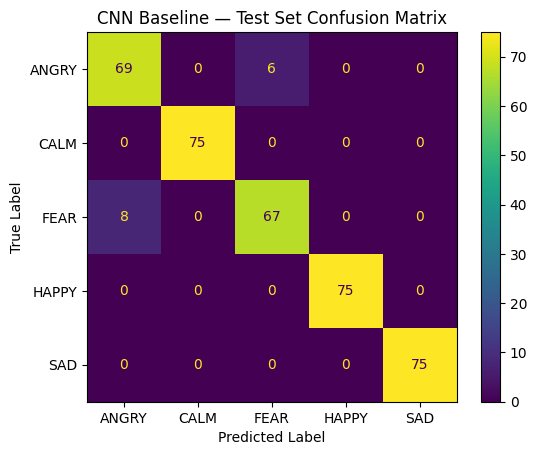

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create CNN baseline confusion matrix
cm_cnn = confusion_matrix(
    cnn_true_labels,
    cnn_pred_labels
)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_cnn,
    display_labels=label_encoder.classes_
)

disp.plot()

plt.title("CNN Baseline — Test Set Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

**MLP Analysis**


In [ ]:
import random
import numpy as np
import tensorflow as tf

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

mlp_model = Sequential([
    Input(shape=(28,)),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(5, activation="softmax")
])

mlp_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

mlp_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 128)            │         3,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,293 (48.02 KB)

 Trainable params: 12,293 (48.02 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history_mlp = mlp_model.fit(
    X_train.reshape(-1, 28),
    y_train_cat,
    validation_data=(
        X_val.reshape(-1, 28),
        y_val_cat
    ),
    epochs=30,
    batch_size=32,
    verbose=1
)

Epoch 1/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6080 - loss: 1.0033 - val_accuracy: 0.8720 - val_loss: 0.4752
Epoch 2/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8703 - loss: 0.3842 - val_accuracy: 0.9413 - val_loss: 0.2145
Epoch 3/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9097 - loss: 0.2399 - val_accuracy: 0.9547 - val_loss: 0.1400
Epoch 4/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9371 - loss: 0.1805 - val_accuracy: 0.9573 - val_loss: 0.1219
Epoch 5/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9314 - loss: 0.1629 - val_accuracy: 0.9627 - val_loss: 0.1071
Epoch 6/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9486 - loss: 0.1276 - val_accuracy: 0.9680 - val_loss: 0.0994
Epoch 7/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9423 - loss: 0.1344 - val_accuracy: 0.9573 - val_loss: 0.1042
Epoch 8/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9566 - loss: 0.1047 - val_accuracy: 0.9680 - val_loss:

In [ ]:
mlp_predictions = mlp_model.predict(
    X_test.reshape(-1, 28)
)

mlp_pred_labels = np.argmax(mlp_predictions, axis=1)
mlp_true_labels = np.argmax(y_test_cat, axis=1)

print("Test samples:", len(mlp_true_labels))
print("Correct predictions:", (mlp_true_labels == mlp_pred_labels).sum())
print("Incorrect predictions:", (mlp_true_labels != mlp_pred_labels).sum())

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Test samples: 375
Correct predictions: 360
Incorrect predictions: 15


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

print("========== MLP BASELINE RESULTS ==========")

print("Accuracy:",
      accuracy_score(mlp_true_labels, mlp_pred_labels))

print("Macro Precision:",
      precision_score(mlp_true_labels, mlp_pred_labels, average="macro"))

print("Macro Recall:",
      recall_score(mlp_true_labels, mlp_pred_labels, average="macro"))

print("Macro F1:",
      f1_score(mlp_true_labels, mlp_pred_labels, average="macro"))

print("Weighted F1:",
      f1_score(mlp_true_labels, mlp_pred_labels, average="weighted"))

print("Balanced Accuracy:",
      balanced_accuracy_score(mlp_true_labels, mlp_pred_labels))

print("\nClassification Report:")
print(
    classification_report(
        mlp_true_labels,
        mlp_pred_labels,
        target_names=label_encoder.classes_
    )
)

print("\nExact Confusion Matrix:")
print(
    confusion_matrix(
        mlp_true_labels,
        mlp_pred_labels
    )
)

========== MLP BASELINE RESULTS ==========
Accuracy: 0.96
Macro Precision: 0.9607142857142857
Macro Recall: 0.96
Macro F1: 0.9599555061179089
Weighted F1: 0.9599555061179088
Balanced Accuracy: 0.96

Classification Report:
              precision    recall  f1-score   support

       ANGRY       0.93      0.87      0.90        75
        CALM       1.00      1.00      1.00        75
        FEAR       0.88      0.93      0.90        75
       HAPPY       1.00      1.00      1.00        75
         SAD       1.00      1.00      1.00        75

    accuracy                           0.96       375
   macro avg       0.96      0.96      0.96       375
weighted avg       0.96      0.96      0.96       375


Exact Confusion Matrix:
[[65  0 10  0  0]
 [ 0 75  0  0  0]
 [ 5  0 70  0  0]
 [ 0  0  0 75  0]
 [ 0  0  0  0 75]]


In [ ]:
print(confusion_matrix(mlp_true_labels, mlp_pred_labels))

[[65  0 10  0  0]
 [ 0 75  0  0  0]
 [ 5  0 70  0  0]
 [ 0  0  0 75  0]
 [ 0  0  0  0 75]]


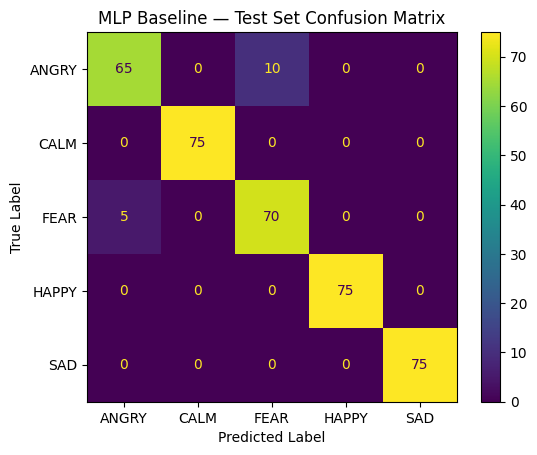

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_mlp = confusion_matrix(
    mlp_true_labels,
    mlp_pred_labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp,
    display_labels=label_encoder.classes_
)

disp.plot()

plt.title("MLP Baseline — Test Set Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

**SVM Baseline**

In [ ]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    probability=True,
    random_state=42
)

svm_model.fit(
    X_train.reshape(-1, 28),
    y_train
)

print("SVM training completed.")

SVM training completed.


In [ ]:
svm_predictions = svm_model.predict(
    X_test.reshape(-1, 28)
)

svm_true_labels = y_test

print("Test samples:", len(svm_true_labels))
print(
    "Correct predictions:",
    (svm_true_labels == svm_predictions).sum()
)
print(
    "Incorrect predictions:",
    (svm_true_labels != svm_predictions).sum()
)

Test samples: 375
Correct predictions: 367
Incorrect predictions: 8


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

print("========== SVM BASELINE RESULTS ==========")

print("Accuracy:",
      accuracy_score(svm_true_labels, svm_predictions))

print("Macro Precision:",
      precision_score(svm_true_labels, svm_predictions, average="macro"))

print("Macro Recall:",
      recall_score(svm_true_labels, svm_predictions, average="macro"))

print("Macro F1:",
      f1_score(svm_true_labels, svm_predictions, average="macro"))

print("Weighted F1:",
      f1_score(svm_true_labels, svm_predictions, average="weighted"))

print("Balanced Accuracy:",
      balanced_accuracy_score(svm_true_labels, svm_predictions))

print("\nClassification Report:")
print(
    classification_report(
        svm_true_labels,
        svm_predictions,
        target_names=label_encoder.classes_
    )
)

print("\nExact Confusion Matrix:")
print(
    confusion_matrix(
        svm_true_labels,
        svm_predictions
    )
)

========== SVM BASELINE RESULTS ==========
Accuracy: 0.9786666666666667
Macro Precision: 0.9798174986580783
Macro Recall: 0.9786666666666667
Macro F1: 0.9786324786324787
Weighted F1: 0.9786324786324785
Balanced Accuracy: 0.9786666666666667

Classification Report:
              precision    recall  f1-score   support

       ANGRY       0.99      0.91      0.94        75
        CALM       1.00      1.00      1.00        75
        FEAR       0.91      0.99      0.95        75
       HAPPY       1.00      1.00      1.00        75
         SAD       1.00      1.00      1.00        75

    accuracy                           0.98       375
   macro avg       0.98      0.98      0.98       375
weighted avg       0.98      0.98      0.98       375


Exact Confusion Matrix:
[[68  0  7  0  0]
 [ 0 75  0  0  0]
 [ 1  0 74  0  0]
 [ 0  0  0 75  0]
 [ 0  0  0  0 75]]


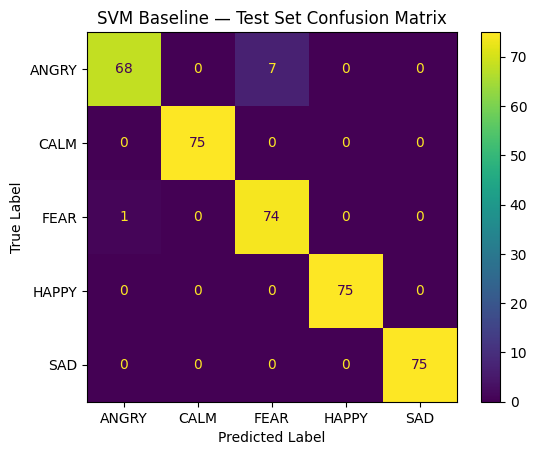

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm_svm = confusion_matrix(
    svm_true_labels,
    svm_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=label_encoder.classes_
)

disp.plot()

plt.title("SVM Baseline — Test Set Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

“Here I implemented my proposed CNN + Attention deep-learning model. First, I used two CNN layers to extract features from the EEG data. Then I applied an Attention mechanism to focus on the important learned features. I combined the original CNN features with the attention output, normalized them, and passed them through fully connected layers to classify the EEG sample into five emotion classes.”

In [ ]:
import tensorflow as tf
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import (
    Conv1D,
    Attention,
    Add,
    LayerNormalization,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)

# Clear previous model/session
tf.keras.backend.clear_session()

# Input: 4 EEG channels × 7 features
inputs = Input(shape=(4, 7))

# CNN feature extraction
x = Conv1D(
    64,
    kernel_size=2,
    activation="relu",
    padding="same"
)(inputs)

x = Conv1D(
    128,
    kernel_size=2,
    activation="relu",
    padding="same"
)(x)

# Self-attention
attention_output = Attention()([x, x])

# Residual connection
x = Add()([x, attention_output])

# Normalize
x = LayerNormalization()(x)

# Pool extracted features
x = GlobalAveragePooling1D()(x)

# Fully connected layers
x = Dense(
    128,
    activation="relu"
)(x)

x = Dropout(0.4)(x)

x = Dense(
    64,
    activation="relu"
)(x)

# Output: 5 emotion classes
outputs = Dense(
    5,
    activation="softmax"
)(x)

# Build model
cnn_attention_model = Model(
    inputs=inputs,
    outputs=outputs
)

# Compile
cnn_attention_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_attention_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 4, 7)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 4, 64)     │        960 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 4, 128)    │     16,512 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, 4, 128)    │          0 │ conv1d_1[0][0],   │
│ (Attention)         │                   │            │ conv1d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 4, 128)    │          0 │ conv1d_1[0][0],   │
│                     │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 4, 128)    │        256 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     16,512 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 5)         │        325 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 42,821 (167.27 KB)

 Trainable params: 42,821 (167.27 KB)

 Non-trainable params: 0 (0.00 B)

“Here I trained my proposed CNN + Attention model using the training EEG dataset. I used the validation dataset to monitor the model's performance during training. The model was trained for 30 epochs with a batch size of 32, and I stored the training history in attention_history so I could later analyze the training and validation accuracy and loss.”

In [ ]:
# Train the CNN + Attention model

attention_history = cnn_attention_model.fit(
    X_train,
    y_train_cat,
    validation_data=(X_val, y_val_cat),
    epochs=30,
    batch_size=32,
    verbose=1
)

print("CNN + Attention training completed successfully.")

Epoch 1/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.8531 - loss: 0.4229 - val_accuracy: 0.9520 - val_loss: 0.1177
Epoch 2/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9446 - loss: 0.1416 - val_accuracy: 0.9573 - val_loss: 0.0992
Epoch 3/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9543 - loss: 0.1125 - val_accuracy: 0.9573 - val_loss: 0.0878
Epoch 4/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9651 - loss: 0.0838 - val_accuracy: 0.9680 - val_loss: 0.0918
Epoch 5/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9629 - loss: 0.0892 - val_accuracy: 0.9653 - val_loss: 0.0887
Epoch 6/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9714 - loss: 0.0729 - val_accuracy: 0.9573 - val_loss: 0.1013
Epoch 7/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9760 - loss: 0.0661 - val_accuracy: 0.9680 - val_loss: 0.0809
Epoch 8/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9789 - loss: 0.0600 - val_accuracy: 0.9680 - val_l

“Here I evaluated my trained CNN + Attention model using the test dataset. I used the 375 test samples that were kept separate from training to measure how well the final model performs on unseen data. The evaluate() function gives me the test loss and test accuracy.”

In [ ]:
# Evaluate CNN + Attention on the unseen test dataset

attention_test_loss, attention_test_accuracy = cnn_attention_model.evaluate(
    X_test,
    y_test_cat,
    batch_size=32,
    verbose=1
)

print("CNN + Attention Test Loss:", attention_test_loss)
print("CNN + Attention Test Accuracy:", attention_test_accuracy)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9760 - loss: 0.1234 
CNN + Attention Test Loss: 0.12343065440654755
CNN + Attention Test Accuracy: 0.9760000109672546


“Here I evaluated my proposed CNN + Attention model using the test dataset and calculated multiple performance metrics. First, the model predicts the five emotion classes for the 375 unseen test samples. I then selected the class with the highest probability using argmax and compared those predictions with the actual test labels. Finally, I calculated accuracy, weighted precision, weighted recall and weighted F1-score.”

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict probabilities on the test data
attention_predictions = cnn_attention_model.predict(
    X_test,
    verbose=0
)

# Convert probabilities to predicted class numbers
attention_pred_labels = np.argmax(
    attention_predictions,
    axis=1
)

# Calculate metrics
attention_accuracy = accuracy_score(
    y_test,
    attention_pred_labels
)

attention_precision = precision_score(
    y_test,
    attention_pred_labels,
    average="weighted"
)

attention_recall = recall_score(
    y_test,
    attention_pred_labels,
    average="weighted"
)

attention_f1 = f1_score(
    y_test,
    attention_pred_labels,
    average="weighted"
)

print("CNN + Attention Accuracy :", attention_accuracy)
print("CNN + Attention Precision:", attention_precision)
print("CNN + Attention Recall   :", attention_recall)
print("CNN + Attention F1-score :", attention_f1)

CNN + Attention Accuracy : 0.976
CNN + Attention Precision: 0.976031294452347
CNN + Attention Recall   : 0.976
CNN + Attention F1-score : 0.9759989332859238


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# True labels
y_true = y_test

# Predicted labels
y_pred = attention_pred_labels

# Metrics
accuracy = accuracy_score(y_true, y_pred)

precision_macro = precision_score(
    y_true, y_pred, average="macro"
)

recall_macro = recall_score(
    y_true, y_pred, average="macro"
)

f1_macro = f1_score(
    y_true, y_pred, average="macro"
)

f1_weighted = f1_score(
    y_true, y_pred, average="weighted"
)

balanced_accuracy = balanced_accuracy_score(
    y_true, y_pred
)

print("========== CNN + ATTENTION RESULTS ==========")

print("Test samples:", len(y_true))
print("Correct predictions:", (y_true == y_pred).sum())
print("Incorrect predictions:", (y_true != y_pred).sum())

print("\nAccuracy:", accuracy)
print("Macro Precision:", precision_macro)
print("Macro Recall:", recall_macro)
print("Macro F1:", f1_macro)
print("Weighted F1:", f1_weighted)
print("Balanced Accuracy:", balanced_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=label_encoder.classes_
    )
)

========== CNN + ATTENTION RESULTS ==========
Test samples: 375
Correct predictions: 366
Incorrect predictions: 9

Accuracy: 0.976
Macro Precision: 0.976031294452347
Macro Recall: 0.976
Macro F1: 0.9759989332859238
Weighted F1: 0.9759989332859238
Balanced Accuracy: 0.976

Classification Report:
              precision    recall  f1-score   support

       ANGRY       0.95      0.93      0.94        75
        CALM       1.00      1.00      1.00        75
        FEAR       0.93      0.95      0.94        75
       HAPPY       1.00      1.00      1.00        75
         SAD       1.00      1.00      1.00        75

    accuracy                           0.98       375
   macro avg       0.98      0.98      0.98       375
weighted avg       0.98      0.98      0.98       375



Exact Confusion Matrix:
[[70  0  5  0  0]
 [ 0 75  0  0  0]
 [ 4  0 71  0  0]
 [ 0  0  0 75  0]
 [ 0  0  0  0 75]]


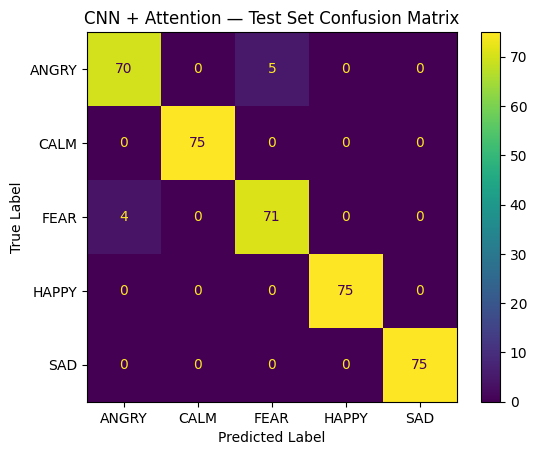

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

print("Exact Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
).plot()

plt.title("CNN + Attention — Test Set Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [ ]:
import pandas as pd

results_df = pd.DataFrame({
    "true_label": label_encoder.inverse_transform(y_true),
    "predicted_label": label_encoder.inverse_transform(y_pred),
    "correct": y_true == y_pred,
    "max_probability": np.max(attention_predictions, axis=1)
})

results_df.to_csv(
    "cnn_attention_test_predictions.csv",
    index=False
)

print("Saved:", len(results_df), "test predictions")

Saved: 375 test predictions


In [ ]:
# Save the final CNN + Attention model

cnn_attention_model.save(
    "cnn_attention_model.keras"
)

print("CNN + Attention model saved successfully.")

CNN + Attention model saved successfully.


In [ ]:
import joblib

# Save preprocessing objects
joblib.dump(
    scaler,
    "scaler.pkl"
)

joblib.dump(
    label_encoder,
    "label_encoder.pkl"
)

print("scaler.pkl saved successfully.")
print("label_encoder.pkl saved successfully.")

scaler.pkl saved successfully.
label_encoder.pkl saved successfully.


In [ ]:
import os

required_files = [
    "cnn_attention_model.keras",
    "scaler.pkl",
    "label_encoder.pkl"
]

print("===== SAVED FILE VERIFICATION =====")

all_present = True

for file_name in required_files:
    if os.path.exists(file_name):
        size_mb = os.path.getsize(file_name) / (1024 * 1024)
        print(f"✓ {file_name} ({size_mb:.2f} MB)")
    else:
        print(f"✗ {file_name} NOT FOUND")
        all_present = False

print()

if all_present:
    print("✅ All required files are ready.")
else:
    print("❌ One or more required files are missing.")

===== SAVED FILE VERIFICATION =====
✓ cnn_attention_model.keras (0.54 MB)
✓ scaler.pkl (0.00 MB)
✓ label_encoder.pkl (0.00 MB)

✅ All required files are ready.


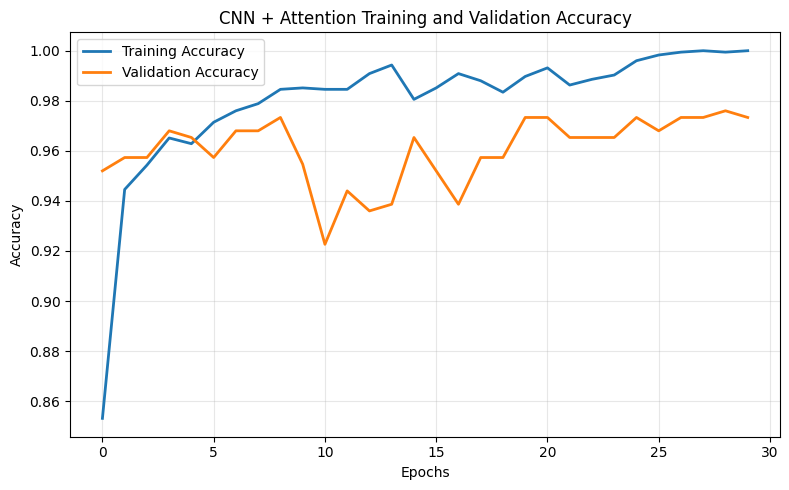

In [ ]:
import matplotlib.pyplot as plt

# Create figure for training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    attention_history.history["accuracy"],
    label="Training Accuracy",
    linewidth=2
)

plt.plot(
    attention_history.history["val_accuracy"],
    label="Validation Accuracy",
    linewidth=2
)

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("CNN + Attention Training and Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "cnn_attention_accuracy_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

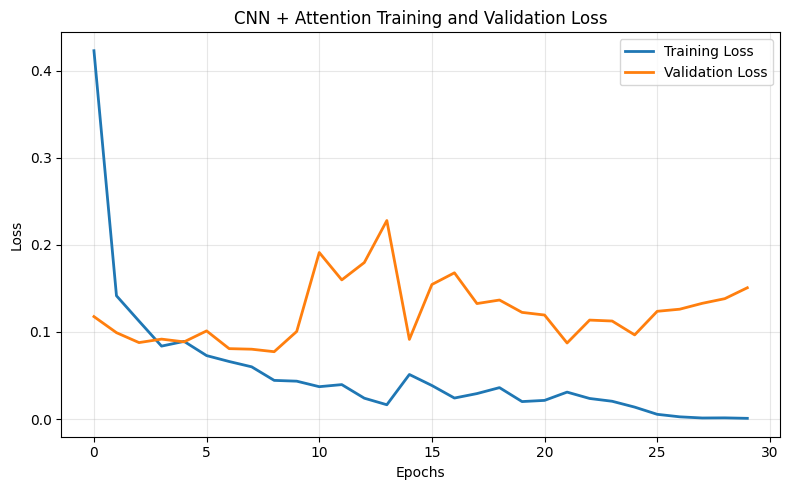

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    attention_history.history["loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    attention_history.history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("CNN + Attention Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "cnn_attention_loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import numpy as np
import random
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D,
    GlobalAveragePooling1D, Dense, Dropout,
    Attention, Add, LayerNormalization
)

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

SEEDS = [42, 123, 2024]

print("Seeds:", SEEDS)

Seeds: [42, 123, 2024]


In [ ]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

In [ ]:
def build_cnn():
    model = Sequential([
        Input(shape=(4, 7)),

        Conv1D(
            filters=64,
            kernel_size=2,
            activation="relu",
            padding="same"
        ),

        MaxPooling1D(pool_size=2),

        Conv1D(
            filters=128,
            kernel_size=2,
            activation="relu",
            padding="same"
        ),

        GlobalAveragePooling1D(),

        Dense(64, activation="relu"),

        Dropout(0.3),

        Dense(5, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [ ]:
def build_cnn_attention():
    inputs = tf.keras.Input(shape=(4, 7))

    x = Conv1D(
        64,
        kernel_size=2,
        activation="relu",
        padding="same"
    )(inputs)

    x = Conv1D(
        128,
        kernel_size=2,
        activation="relu",
        padding="same"
    )(x)

    attention_output = Attention()([x, x])

    x = Add()([x, attention_output])

    x = LayerNormalization()(x)

    x = GlobalAveragePooling1D()(x)

    x = Dense(128, activation="relu")(x)

    x = Dropout(0.4)(x)

    x = Dense(64, activation="relu")(x)

    outputs = Dense(5, activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs)

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [ ]:
def build_mlp():
    model = Sequential([
        Input(shape=(28,)),

        Dense(128, activation="relu"),
        Dropout(0.3),

        Dense(64, activation="relu"),
        Dropout(0.3),

        Dense(5, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [ ]:
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score
)

SEEDS = [42, 123, 2024]

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)

print("Setup completed")

Setup completed


In [ ]:

def build_cnn_attention():
    inputs = tf.keras.Input(shape=(4, 7))

    x = tf.keras.layers.Conv1D(
        64, kernel_size=2, activation="relu", padding="same"
    )(inputs)

    x = tf.keras.layers.Conv1D(
        128, kernel_size=2, activation="relu", padding="same"
    )(x)

    attention_output = tf.keras.layers.Attention()([x, x])

    x = tf.keras.layers.Add()([x, attention_output])
    x = tf.keras.layers.LayerNormalization()(x)
    x = tf.keras.layers.GlobalAveragePooling1D()(x)

    x = tf.keras.layers.Dense(128, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.4)(x)
    x = tf.keras.layers.Dense(64, activation="relu")(x)

    outputs = tf.keras.layers.Dense(5, activation="softmax")(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs)

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

print("CNN + Attention function defined successfully.")


CNN + Attention function defined successfully.


In [ ]:
results = []

for seed in SEEDS:

    print("\n" + "="*60)
    print("SEED:", seed)
    print("="*60)

    set_seed(seed)

    # -------------------------
    # CNN
    # -------------------------
    cnn = build_cnn()

    cnn.fit(
        X_train,
        y_train_cat,
        validation_data=(X_val, y_val_cat),
        epochs=30,
        batch_size=32,
        verbose=0
    )

    cnn_prob = cnn.predict(X_test, verbose=0)
    cnn_pred = np.argmax(cnn_prob, axis=1)

    cnn_acc = accuracy_score(y_test, cnn_pred)
    cnn_f1 = f1_score(y_test, cnn_pred, average="macro")
    cnn_bal = balanced_accuracy_score(y_test, cnn_pred)

    results.append([
        seed, "CNN", cnn_acc, cnn_f1, cnn_bal
    ])


    # -------------------------
    # CNN + ATTENTION
    # -------------------------
    set_seed(seed)

    cnn_att = build_cnn_attention()

    cnn_att.fit(
        X_train,
        y_train_cat,
        validation_data=(X_val, y_val_cat),
        epochs=30,
        batch_size=32,
        verbose=0
    )

    att_prob = cnn_att.predict(X_test, verbose=0)
    att_pred = np.argmax(att_prob, axis=1)

    att_acc = accuracy_score(y_test, att_pred)
    att_f1 = f1_score(y_test, att_pred, average="macro")
    att_bal = balanced_accuracy_score(y_test, att_pred)

    results.append([
        seed, "CNN + Attention", att_acc, att_f1, att_bal
    ])


    # -------------------------
    # MLP
    # -------------------------
    set_seed(seed)

    mlp = build_mlp()

    mlp.fit(
        X_train.reshape(-1, 28),
        y_train_cat,
        validation_data=(
            X_val.reshape(-1, 28),
            y_val_cat
        ),
        epochs=30,
        batch_size=32,
        verbose=0
    )

    mlp_prob = mlp.predict(
        X_test.reshape(-1, 28),
        verbose=0
    )

    mlp_pred = np.argmax(mlp_prob, axis=1)

    mlp_acc = accuracy_score(y_test, mlp_pred)
    mlp_f1 = f1_score(y_test, mlp_pred, average="macro")
    mlp_bal = balanced_accuracy_score(y_test, mlp_pred)

    results.append([
        seed, "MLP", mlp_acc, mlp_f1, mlp_bal
    ])


    # -------------------------
    # SVM
    # -------------------------
    svm = SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        random_state=seed
    )

    svm.fit(
        X_train.reshape(-1, 28),
        y_train
    )

    svm_pred = svm.predict(
        X_test.reshape(-1, 28)
    )

    svm_acc = accuracy_score(y_test, svm_pred)
    svm_f1 = f1_score(y_test, svm_pred, average="macro")
    svm_bal = balanced_accuracy_score(y_test, svm_pred)

    results.append([
        seed, "SVM", svm_acc, svm_f1, svm_bal
    ])


print("\nAll experiments completed.")


SEED: 42

SEED: 123

SEED: 2024

All experiments completed.


In [ ]:
import pandas as pd

results_df = pd.DataFrame(
    results,
    columns=[
        "Seed",
        "Model",
        "Accuracy",
        "Macro F1",
        "Balanced Accuracy"
    ]
)

print(results_df)

   Seed Model  Accuracy  Macro F1  Balanced Accuracy
0    42   CNN  0.970667  0.970655           0.970667


In [ ]:
summary_df = results_df.groupby("Model").agg(
    Accuracy_mean=("Accuracy", "mean"),
    Accuracy_std=("Accuracy", "std"),

    Macro_F1_mean=("Macro F1", "mean"),
    Macro_F1_std=("Macro F1", "std"),

    Balanced_Accuracy_mean=("Balanced Accuracy", "mean"),
    Balanced_Accuracy_std=("Balanced Accuracy", "std")
).reset_index()

print(summary_df)

             Model  Accuracy_mean  Accuracy_std  Macro_F1_mean  Macro_F1_std  \
0              CNN       0.968000      0.004619       0.967972      0.004647   
1  CNN + Attention       0.973333      0.002667       0.973313      0.002639   
2              MLP       0.960889      0.004073       0.960859      0.004061   
3              SVM       0.978667      0.000000       0.978632      0.000000   

   Balanced_Accuracy_mean  Balanced_Accuracy_std  
0                0.968000               0.004619  
1                0.973333               0.002667  
2                0.960889               0.004073  
3                0.978667               0.000000  


**experiment 5**


In [ ]:
y_prob = cnn_attention_model.predict(X_test, verbose=0)

y_pred = np.argmax(y_prob, axis=1)

confidence = np.max(y_prob, axis=1)

correct = (y_pred == y_test)

print("Test samples:", len(y_test))
print("Average confidence:", np.mean(confidence))
print("Correct predictions:", np.sum(correct))
print("Incorrect predictions:", np.sum(~correct))

Test samples: 375
Average confidence: 0.9959178
Correct predictions: 366
Incorrect predictions: 9


In [ ]:
import numpy as np

def calculate_ece(y_true, y_prob, n_bins=10):

    confidences = np.max(y_prob, axis=1)
    predictions = np.argmax(y_prob, axis=1)

    accuracies = predictions == y_true

    ece = 0.0

    bin_edges = np.linspace(0, 1, n_bins + 1)

    for i in range(n_bins):

        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        if i == n_bins - 1:
            mask = (confidences >= lower) & (confidences <= upper)
        else:
            mask = (confidences >= lower) & (confidences < upper)

        if np.sum(mask) > 0:

            bin_accuracy = np.mean(accuracies[mask])
            bin_confidence = np.mean(confidences[mask])
            bin_size = np.sum(mask)

            ece += (
                bin_size / len(y_true)
            ) * abs(
                bin_accuracy - bin_confidence
            )

    return ece


ece = calculate_ece(
    y_test,
    y_prob,
    n_bins=10
)

print("Expected Calibration Error (ECE):", ece)

Expected Calibration Error (ECE): 0.0211655241648356


In [ ]:
from sklearn.preprocessing import label_binarize

y_test_onehot = label_binarize(
    y_test,
    classes=np.arange(5)
)

brier_score = np.mean(
    np.sum(
        (y_prob - y_test_onehot) ** 2,
        axis=1
    )
)

print("Brier Score:", brier_score)

Brier Score: 0.042246517506640005


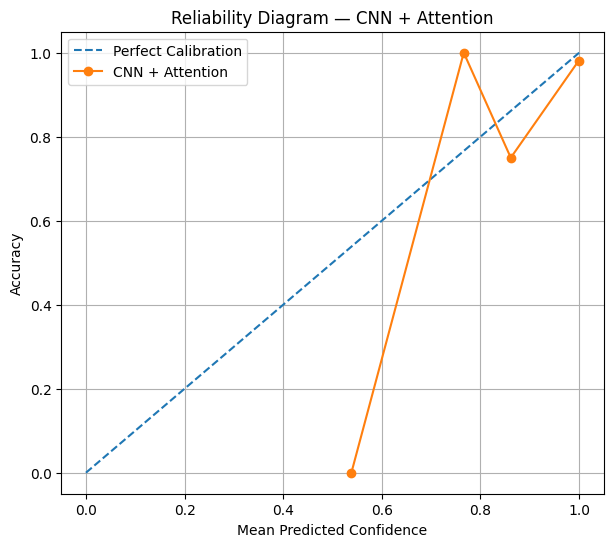

In [ ]:
import matplotlib.pyplot as plt

def reliability_data(y_true, y_prob, n_bins=10):

    confidences = np.max(y_prob, axis=1)
    predictions = np.argmax(y_prob, axis=1)

    correct = predictions == y_true

    bin_edges = np.linspace(0, 1, n_bins + 1)

    bin_confidences = []
    bin_accuracies = []

    for i in range(n_bins):

        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        if i == n_bins - 1:
            mask = (confidences >= lower) & (confidences <= upper)
        else:
            mask = (confidences >= lower) & (confidences < upper)

        if np.sum(mask) > 0:

            bin_confidences.append(
                np.mean(confidences[mask])
            )

            bin_accuracies.append(
                np.mean(correct[mask])
            )

    return bin_confidences, bin_accuracies


bin_conf, bin_acc = reliability_data(
    y_test,
    y_prob,
    n_bins=10
)

plt.figure(figsize=(7, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.plot(
    bin_conf,
    bin_acc,
    marker="o",
    label="CNN + Attention"
)

plt.xlabel("Mean Predicted Confidence")
plt.ylabel("Accuracy")
plt.title("Reliability Diagram — CNN + Attention")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
print("========== CONFIDENCE CALIBRATION ==========")
print(f"ECE: {ece:.4f}")
print(f"Brier Score: {brier_score:.4f}")
print(f"Average Confidence: {np.mean(confidence):.4f}")

========== CONFIDENCE CALIBRATION ==========
ECE: 0.0212
Brier Score: 0.0422
Average Confidence: 0.9959


In [ ]:
import pandas as pd

df_test = pd.read_csv("emotions synthetic 5class.csv")

# Remove one required feature
missing_columns = df_test.drop(columns=["TP9_delta"])

missing_columns.to_csv(
    "test_missing_column.csv",
    index=False
)

print("Created:", "test_missing_column.csv")
print("Columns remaining:", len(missing_columns.columns))

Created: test_missing_column.csv
Columns remaining: 28


In [ ]:
import pandas as pd

df_test = pd.read_csv("emotions synthetic 5class.csv")

non_numeric = df_test.copy()

non_numeric.loc[0, "TP9_delta"] = "abc"

non_numeric.to_csv(
    "test_non_numeric.csv",
    index=False
)

print("Created test_non_numeric.csv")

Created test_non_numeric.csv


/tmp/ipykernel_1032/1042892021.py:7: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'abc' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  non_numeric.loc[0, "TP9_delta"] = "abc"


In [ ]:
import pandas as pd
import numpy as np

df_test = pd.read_csv("emotions synthetic 5class.csv")

nan_test = df_test.copy()
nan_test.loc[0, "TP9_delta"] = np.nan

nan_test.to_csv("test_nan.csv", index=False)

print("Created test_nan.csv")

Created test_nan.csv


In [ ]:
import pandas as pd
import numpy as np

df_test = pd.read_csv("emotions synthetic 5class.csv")

inf_test = df_test.copy()
inf_test.loc[0, "TP9_delta"] = np.inf

inf_test.to_csv("test_infinity.csv", index=False)

print("Created test_infinity.csv")

Created test_infinity.csv


In [ ]:
import pandas as pd

df_test = pd.read_csv("emotions synthetic 5class.csv")

empty_test = df_test.iloc[0:0]

empty_test.to_csv("test_empty.csv", index=False)

print("Created test_empty.csv")

Created test_empty.csv


In [ ]:
import pandas as pd

df_test = pd.read_csv("emotions synthetic 5class.csv")

duplicate_test = df_test.copy()

# Add a duplicate of an existing feature
duplicate_test["TP9_delta_duplicate"] = duplicate_test["TP9_delta"]

duplicate_test.to_csv(
    "test_duplicate_column.csv",
    index=False
)

print("Created test_duplicate_column.csv")

Created test_duplicate_column.csv


In [ ]:
import pandas as pd

df_test = pd.read_csv("emotions synthetic 5class.csv")

# Keep label at the end, but reverse the order of all 28 features
feature_columns = [col for col in df_test.columns if col != "label"]

reordered_test = df_test[
    feature_columns[::-1] + ["label"]
]

reordered_test.to_csv(
    "test_reordered_columns.csv",
    index=False
)

print("Created test_reordered_columns.csv")
print(reordered_test.columns.tolist())

Created test_reordered_columns.csv
['TP10_std', 'TP10_mean', 'TP10_gamma', 'TP10_beta', 'TP10_alpha', 'TP10_theta', 'TP10_delta', 'AF8_std', 'AF8_mean', 'AF8_gamma', 'AF8_beta', 'AF8_alpha', 'AF8_theta', 'AF8_delta', 'AF7_std', 'AF7_mean', 'AF7_gamma', 'AF7_beta', 'AF7_alpha', 'AF7_theta', 'AF7_delta', 'TP9_std', 'TP9_mean', 'TP9_gamma', 'TP9_beta', 'TP9_alpha', 'TP9_theta', 'TP9_delta', 'label']


In [ ]:
import pandas as pd
import numpy as np

df_test = pd.read_csv("emotions synthetic 5class.csv")

invalid_batch = df_test.iloc[:20].copy()

invalid_batch.loc[3, "TP9_delta"] = np.nan
invalid_batch.loc[7, "AF7_alpha"] = np.nan
invalid_batch.loc[12, "TP10_beta"] = np.inf

invalid_batch.to_csv(
    "test_invalid_batch.csv",
    index=False
)

print("Created test_invalid_batch.csv")

Created test_invalid_batch.csv


In [ ]:
import time
import tensorflow as tf

start_time = time.perf_counter()

model = tf.keras.models.load_model("cnn_attention_model.keras")

end_time = time.perf_counter()

load_time = end_time - start_time

print(f"Model load time: {load_time:.4f} seconds")

Model load time: 0.2791 seconds


In [ ]:
import time
import numpy as np

# Take one test sample
sample = X_test[0:1]

# Warm-up prediction
model.predict(sample, verbose=0)

# Measure inference time
times = []

for _ in range(100):
    start = time.perf_counter()
    model.predict(sample, verbose=0)
    end = time.perf_counter()
    times.append(end - start)

avg_latency = np.mean(times)
std_latency = np.std(times)

print(f"Average single-record inference latency: {avg_latency:.6f} seconds")
print(f"Standard deviation: {std_latency:.6f} seconds")
print(f"Average latency in milliseconds: {avg_latency * 1000:.3f} ms")

Average single-record inference latency: 0.099611 seconds
Standard deviation: 0.024201 seconds
Average latency in milliseconds: 99.611 ms


In [ ]:
import time

# Use the complete test set
batch = X_test

# Warm-up
model.predict(batch, verbose=0)

# Measure batch prediction
start_time = time.perf_counter()

predictions = model.predict(batch, verbose=0)

end_time = time.perf_counter()

total_time = end_time - start_time
num_samples = len(batch)

throughput = num_samples / total_time

print(f"Batch size: {num_samples}")
print(f"Total batch inference time: {total_time:.6f} seconds")
print(f"Batch throughput: {throughput:.2f} samples/second")

Batch size: 375
Total batch inference time: 0.366015 seconds
Batch throughput: 1024.55 samples/second


In [ ]:
sample = X_test[0:1]

prediction = model.predict(sample, verbose=0)

predicted_class = np.argmax(prediction, axis=1)[0]
confidence = np.max(prediction, axis=1)[0]

predicted_label = label_encoder.inverse_transform([predicted_class])[0]

print("Notebook emotion:", predicted_label)
print("Notebook confidence:", f"{confidence*100:.2f}%")

Notebook emotion: CALM
Notebook confidence: 100.00%


In [ ]:
print("X_test shape:", X_test.shape)
print("First test sample:")
print(X_test[0])

X_test shape: (375, 4, 7)
First test sample:
[[-1.17142449 -0.8932969   0.77797706 -0.7989246  -1.49612744 -0.98579595
   1.22935575]
 [-1.18953513 -0.08747418  1.86133489 -0.56855496 -0.82516499 -1.48012152
   1.19974094]
 [-0.91418166 -1.01987236  2.12412574 -1.30224935 -0.73349396 -1.96228298
  -1.03998593]
 [ 0.20977285  0.63721538  2.05334519 -0.83770089 -0.88442689  0.48546377
  -0.50315538]]


In [ ]:
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

print("Feature columns:")
print(feature_cols)

X_train: (1750, 4, 7)
X_val: (375, 4, 7)
X_test: (375, 4, 7)
y_train: (1750,)
y_val: (375,)
y_test: (375,)
Feature columns:
['TP9_delta', 'TP9_theta', 'TP9_alpha', 'TP9_beta', 'TP9_gamma', 'TP9_mean', 'TP9_std', 'AF7_delta', 'AF7_theta', 'AF7_alpha', 'AF7_beta', 'AF7_gamma', 'AF7_mean', 'AF7_std', 'AF8_delta', 'AF8_theta', 'AF8_alpha', 'AF8_beta', 'AF8_gamma', 'AF8_mean', 'AF8_std', 'TP10_delta', 'TP10_theta', 'TP10_alpha', 'TP10_beta', 'TP10_gamma', 'TP10_mean', 'TP10_std']


In [ ]:
import numpy as np

# Original test data
X_test_original = X_test.copy()

# Channel order:
# 0 = TP9
# 1 = AF7
# 2 = AF8
# 3 = TP10

channel_permutations = {
    "Original": [0, 1, 2, 3],
    "AF7-TP9-AF8-TP10": [1, 0, 2, 3],
    "TP10-AF8-AF7-TP9": [3, 2, 1, 0],
    "AF8-TP10-TP9-AF7": [2, 3, 0, 1]
}

print("===== CHANNEL-ROW PERMUTATION RESULTS =====")

for name, order in channel_permutations.items():

    X_perm = X_test_original[:, order, :]

    probs = cnn_attention_model.predict(
        X_perm,
        verbose=0
    )

    pred = np.argmax(probs, axis=1)

    accuracy = np.mean(pred == y_test)

    print(f"{name}: {accuracy:.4f} ({accuracy*100:.2f}%)")

===== CHANNEL-ROW PERMUTATION RESULTS =====
Original: 0.9760 (97.60%)
AF7-TP9-AF8-TP10: 0.9733 (97.33%)
TP10-AF8-AF7-TP9: 0.9707 (97.07%)
AF8-TP10-TP9-AF7: 0.9707 (97.07%)


In [ ]:
# Descriptor order:
# 0 = delta
# 1 = theta
# 2 = alpha
# 3 = beta
# 4 = gamma
# 5 = mean
# 6 = std

descriptor_permutations = {
    "Original": [0, 1, 2, 3, 4, 5, 6],
    "Reverse": [6, 5, 4, 3, 2, 1, 0],
    "Shifted": [1, 2, 3, 4, 5, 6, 0],
    "Mixed": [2, 0, 4, 1, 6, 3, 5]
}

print("===== DESCRIPTOR-COLUMN PERMUTATION RESULTS =====")

for name, order in descriptor_permutations.items():

    X_perm = X_test_original[:, :, order]

    probs = cnn_attention_model.predict(
        X_perm,
        verbose=0
    )

    pred = np.argmax(probs, axis=1)

    accuracy = np.mean(pred == y_test)

    print(f"{name}: {accuracy:.4f} ({accuracy*100:.2f}%)")

===== DESCRIPTOR-COLUMN PERMUTATION RESULTS =====
Original: 0.9760 (97.60%)
Reverse: 0.2800 (28.00%)
Shifted: 0.2160 (21.60%)
Mixed: 0.0133 (1.33%)


In [ ]:
import numpy as np
import tensorflow as tf

from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D, GlobalAveragePooling1D,
    Dense, Dropout, Attention, Add, LayerNormalization
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ============================================================
# CHANNEL REMOVAL EXPERIMENT
# ============================================================

channel_names = ["TP9", "AF7", "AF8", "TP10"]

results_channel_removal = []

for remove_idx, remove_name in enumerate(channel_names):

    print("\n" + "=" * 60)
    print(f"Removing channel: {remove_name}")
    print("=" * 60)

    # Remove one channel from the 4x7 representation
    keep_indices = [i for i in range(4) if i != remove_idx]

    X_train_3ch = X_train[:, keep_indices, :]
    X_val_3ch   = X_val[:, keep_indices, :]
    X_test_3ch  = X_test[:, keep_indices, :]

    print("Train shape:", X_train_3ch.shape)
    print("Validation shape:", X_val_3ch.shape)
    print("Test shape:", X_test_3ch.shape)

    # --------------------------------------------------------
    # Build CNN + Attention for 3x7 input
    # --------------------------------------------------------

    inputs = Input(shape=(3, 7))

    x = Conv1D(
        filters=64,
        kernel_size=3,
        activation="relu",
        padding="same"
    )(inputs)

    x = Conv1D(
        filters=128,
        kernel_size=3,
        activation="relu",
        padding="same"
    )(x)

    # Self-attention
    attention_output = Attention()([x, x])

    # Residual connection
    x = Add()([x, attention_output])

    x = LayerNormalization()(x)

    x = GlobalAveragePooling1D()(x)

    x = Dense(128, activation="relu")(x)
    x = Dropout(0.4)(x)

    x = Dense(64, activation="relu")(x)

    outputs = Dense(5, activation="softmax")(x)

    channel_model = Model(inputs, outputs)

    channel_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    channel_model.fit(
        X_train_3ch,
        y_train,
        validation_data=(X_val_3ch, y_val),
        epochs=50,
        batch_size=32,
        callbacks=[early_stop],
        verbose=0
    )

    # --------------------------------------------------------
    # Evaluate
    # --------------------------------------------------------

    probabilities = channel_model.predict(
        X_test_3ch,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    precision = precision_score(
        y_test,
        predictions,
        average="macro"
    )

    recall = recall_score(
        y_test,
        predictions,
        average="macro"
    )

    f1 = f1_score(
        y_test,
        predictions,
        average="macro"
    )

    results_channel_removal.append({
        "Removed Channel": remove_name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1
    })

    print(f"Accuracy       : {accuracy:.4f}")
    print(f"Macro Precision: {precision:.4f}")
    print(f"Macro Recall   : {recall:.4f}")
    print(f"Macro F1       : {f1:.4f}")


# ============================================================
# FINAL RESULTS TABLE
# ============================================================

import pandas as pd

channel_results_df = pd.DataFrame(
    results_channel_removal
)

print("\n")
print("=" * 70)
print("FINAL CHANNEL REMOVAL RESULTS")
print("=" * 70)

display(channel_results_df)


Removing channel: TP9
Train shape: (1750, 3, 7)
Validation shape: (375, 3, 7)
Test shape: (375, 3, 7)
Accuracy       : 0.9387
Macro Precision: 0.9384
Macro Recall   : 0.9387
Macro F1       : 0.9384

Removing channel: AF7
Train shape: (1750, 3, 7)
Validation shape: (375, 3, 7)
Test shape: (375, 3, 7)
Accuracy       : 0.9467
Macro Precision: 0.9471
Macro Recall   : 0.9467
Macro F1       : 0.9464

Removing channel: AF8
Train shape: (1750, 3, 7)
Validation shape: (375, 3, 7)
Test shape: (375, 3, 7)
Accuracy       : 0.9680
Macro Precision: 0.9679
Macro Recall   : 0.9680
Macro F1       : 0.9679

Removing channel: TP10
Train shape: (1750, 3, 7)
Validation shape: (375, 3, 7)
Test shape: (375, 3, 7)
Accuracy       : 0.9600
Macro Precision: 0.9597
Macro Recall   : 0.9600
Macro F1       : 0.9598


FINAL CHANNEL REMOVAL RESULTS


,Removed Channel,Accuracy,Macro Precision,Macro Recall,Macro F1
0,TP9,0.938667,0.938422,0.938667,0.938436
1,AF7,0.946667,0.947079,0.946667,0.946382
2,AF8,0.968000,0.967880,0.968000,0.967890
3,TP10,0.960000,0.959670,0.960000,0.959785


========== MODEL COMPARISON ==========


,Accuracy,Macro Precision,Macro Recall,Macro F1-score,Balanced Accuracy
Model,,,,,
CNN,96.27,96.28,96.27,96.27,96.27
CNN + Attention,97.60,97.60,97.60,97.60,97.60
MLP,96.00,96.07,96.00,96.00,96.00
SVM,97.87,97.98,97.87,97.86,97.87


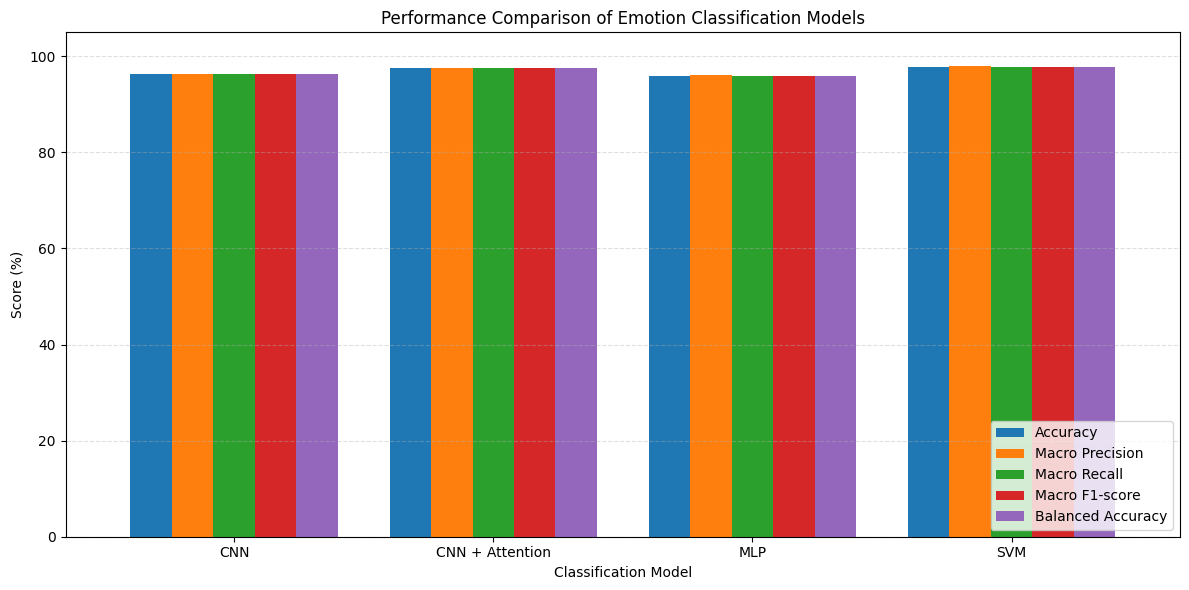

Graph saved as model_comparison_graph.png


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

# Get predictions from all four trained models
cnn_pred = np.argmax(cnn_model.predict(X_test, verbose=0), axis=1)

attention_pred = np.argmax(
    cnn_attention_model.predict(X_test, verbose=0), axis=1
)

mlp_pred = np.argmax(
    mlp_model.predict(X_test.reshape(-1, 28), verbose=0), axis=1
)

svm_pred = svm_model.predict(X_test.reshape(-1, 28))

# True labels
y_true = y_test

# Calculate metrics for each model
models = {
    "CNN": cnn_pred,
    "CNN + Attention": attention_pred,
    "MLP": mlp_pred,
    "SVM": svm_pred
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Macro Precision": precision_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "Macro F1-score": f1_score(
            y_true, predictions, average="macro", zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true, predictions
        )
    })

results_df = pd.DataFrame(results).set_index("Model")

# Print comparison table
print("========== MODEL COMPARISON ==========")
display((results_df * 100).round(2))

# Plot grouped bar chart
ax = (results_df * 100).plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Performance Comparison of Emotion Classification Models")
plt.xlabel("Classification Model")
plt.ylabel("Score (%)")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

# Save a high-resolution graph for the research paper
plt.savefig(
    "model_comparison_graph.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved as model_comparison_graph.png")


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-score,Balanced Accuracy
0,CNN,0.9627,0.9637,0.9627,0.9626,0.9627
1,CNN + Attention,0.9707,0.9707,0.9707,0.9707,0.9707
2,MLP,0.9653,0.9661,0.9653,0.9653,0.9653
3,SVM,0.9787,0.9798,0.9787,0.9786,0.9787


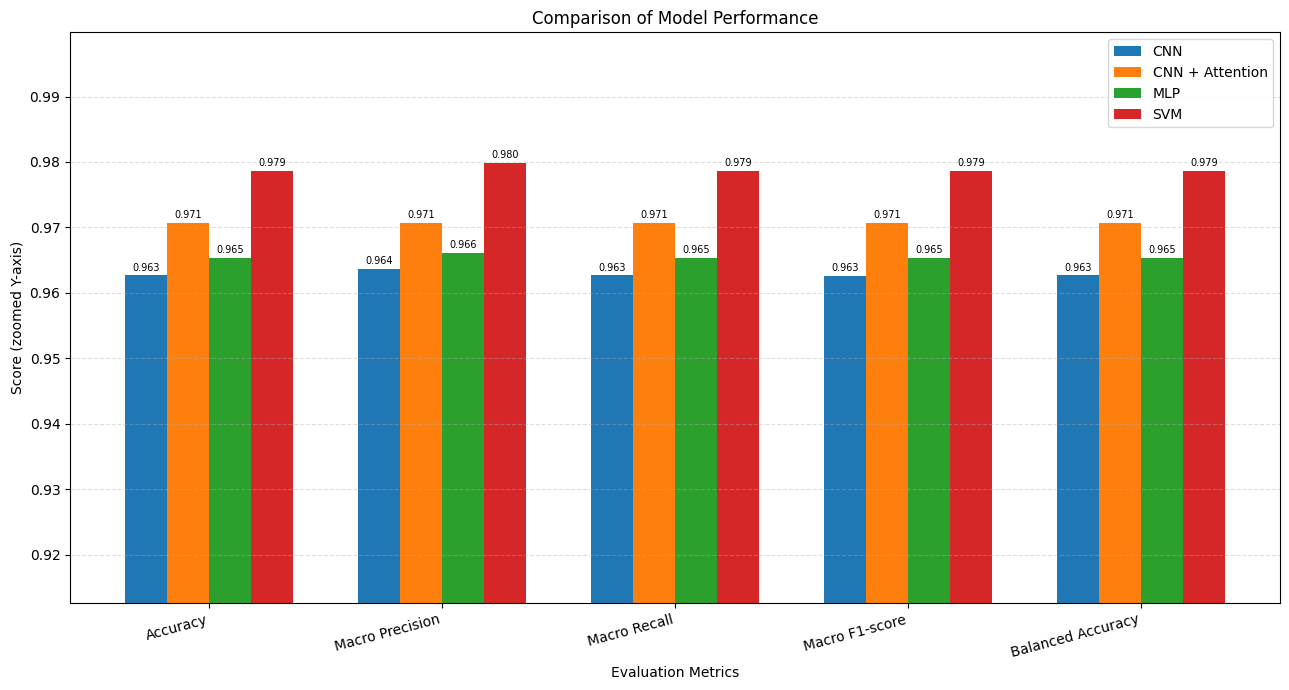

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

# Add your trained models here.
# Make sure these variable names match your notebook.
models_dict = {
    "CNN": cnn,
    "CNN + Attention": cnn_att,
    "MLP": mlp,
    "SVM": svm
}

# Prepare test data for neural networks
X_test_cnn = X_test.reshape(-1, 4, 7)

# Convert one-hot labels to class IDs if needed
y_true = np.argmax(y_test, axis=1) if np.ndim(y_test) > 1 else y_test

results = []

for name, model in models_dict.items():
    if name in ["CNN", "CNN + Attention"]:
        predictions = model.predict(X_test_cnn, verbose=0)
        y_pred = np.argmax(predictions, axis=1)
    elif name == "MLP":
        predictions = model.predict(X_test.reshape(len(X_test), -1), verbose=0)
        y_pred = np.argmax(predictions, axis=1)
    else:
        y_pred = model.predict(X_test.reshape(len(X_test), -1))

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1-score": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred)
    })

comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))

# Plot with a zoomed Y-axis to show small differences
metrics = [
    "Accuracy", "Macro Precision", "Macro Recall",
    "Macro F1-score", "Balanced Accuracy"
]

all_scores = comparison_df[metrics].to_numpy().flatten()
x = np.arange(len(metrics))
width = 0.18

fig, ax = plt.subplots(figsize=(13, 7))

for i, row in comparison_df.iterrows():
    positions = x + (i - (len(comparison_df) - 1) / 2) * width
    bars = ax.bar(positions, row[metrics].values, width, label=row["Model"])
    ax.bar_label(bars, fmt="%.3f", fontsize=7, padding=2)

lower = max(0, float(all_scores.min()) - 0.05)
upper = min(1.05, float(all_scores.max()) + 0.02)

ax.set_ylim(lower, upper)
ax.set_ylabel("Score (zoomed Y-axis)")
ax.set_xlabel("Evaluation Metrics")
ax.set_title("Comparison of Model Performance")
ax.set_xticks(x)
ax.set_xticklabels(metrics, rotation=15, ha="right")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("model_comparison_graph.png", dpi=300, bbox_inches="tight")
plt.show()